In [1]:
# !pip install -q git+https://github.com/tensorflow/examples.git

In [2]:
from __future__ import absolute_import, division, print_function, unicode_literals

import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from scipy import ndimage as ndi
from tqdm import tqdm

import tensorflow as tf
from keras import backend as K
from keras.models import load_model
from tensorflow_examples.models.pix2pix import pix2pix
from tensorflow.keras.metrics import MeanIoU
from IPython.display import clear_output

from skimage import filters, morphology
from skimage.color.adapt_rgb import adapt_rgb, each_channel
from skimage.io import imread
from skimage.transform import resize
from sklearn.model_selection import train_test_split

from commons import binarize_image, find_bighest_cluster, load_images_from_directory_resize, plot

2023-03-14 15:24:59.488930: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-03-14 15:24:59.730406: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2023-03-14 15:24:59.730420: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2023-03-14 15:25:00.637026: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory
2023-

In [4]:
@adapt_rgb(each_channel)
def merge_image_mask(image, mask):
    return image * mask

def create_mask(pred_mask):
    
    pred_mask = tf.argmax(pred_mask, axis=-1)
    pred_mask = pred_mask[..., tf.newaxis]
    
    return np.asarray(pred_mask).reshape(DIM, DIM)

def smoothing_mask(mask):
    mask = find_bighest_cluster(mask)
    
    mask = morphology.closing(mask, morphology.disk(9))

    mask = ndi.binary_fill_holes(mask)

    mask = filters.gaussian(mask, sigma=0.5)

    return binarize_image(mask)

def dice_coef(y_true, y_pred, smooth=1):
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef(y_true, y_pred, smooth=1):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

def plot_cnn_metrics(history):
    
    plt.figure(figsize=(10, 8))
    plt.grid(True)
    

    markers = ["D", "o", "X", "*", "H", "d", "P", "p", "<", ">", "."]
    keys = history.history.keys()
    lengeds = []
    for index, key in enumerate(keys):
        
        if "loss" in key or "lr" in key: continue
        
        plt.plot(history.history[key], marker=markers[index], lw=1)
        lengeds.append(key)

    plt.legend(lengeds)

    plt.xlabel('Epochs ')
    plt.ylabel('Metric')

    plt.title("Treino")

In [5]:
DIM = 224

In [6]:
def unet_model():
    
    base_model = tf.keras.applications.MobileNetV2(input_shape=[DIM, DIM, 3], include_top=False)

    # Use as ativações dessas camadas
    layer_names = [
        'block_1_expand_relu',   # 64x64
        'block_3_expand_relu',   # 32x32
        'block_6_expand_relu',   # 16x16
        'block_13_expand_relu',  # 8x8
        'block_16_project',      # 4x4
    ]
    
    layers = [base_model.get_layer(name).output for name in layer_names]

    # Crie o modelo de extração de características
    down_stack = tf.keras.Model(inputs=base_model.input, outputs=layers)

    down_stack.trainable = False
    
    up_stack = [
        pix2pix.upsample(512, 3),  # 4x4 -> 8x8
        pix2pix.upsample(256, 3),  # 8x8 -> 16x16
        pix2pix.upsample(128, 3),  # 16x16 -> 32x32
        pix2pix.upsample(64, 3),   # 32x32 -> 64x64
    ]

    inputs = tf.keras.layers.Input(shape=[DIM, DIM, 3])
    x = inputs

    # Downsampling através do modelo
    skips = down_stack(x)
    x = skips[-1]
    skips = reversed(skips[:-1])

    # Upsampling e estabelecimento das conexões de salto
    for up, skip in zip(up_stack, skips):
        x = up(x)
        concat = tf.keras.layers.Concatenate()
        x = concat([x, skip])

            
    # # Esta é a última camada do modelo
    last = tf.keras.layers.Conv2DTranspose(1,
                                           3,
                                           strides=2,
                                           padding='same', 
                                           activation='sigmoid')(x)

    return tf.keras.Model(inputs=inputs, outputs=last)

In [7]:
def vanila_unet():
    
    def conv_block(input, num_filters):
        
        x = tf.keras.layers.Conv2D(num_filters, 3, padding="same")(input)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)

        x = tf.keras.layers.Conv2D(num_filters, 3, padding="same")(x)
        x = tf.keras.layers.BatchNormalization()(x)
        
        return tf.keras.layers.Activation("relu")(x)

    def encoder_block(input, num_filters):
        x = conv_block(input, num_filters)
        p = tf.keras.layers.MaxPool2D((2, 2))(x)
        
        return x, p


    def decoder_block(input, skip_features, num_filters):
        x = tf.keras.layers.Conv2DTranspose(num_filters, 
                                            (2, 2), 
                                            strides=2,
                                            padding="same")(input)
        x = tf.keras.layers.Concatenate()([x, skip_features])
        
        return conv_block(x, num_filters)


    inputs = Input(shape=[DIM, DIM, 3])

    s1, p1 = encoder_block(inputs, 64)
    s2, p2 = encoder_block(p1, 128)
    s3, p3 = encoder_block(p2, 256)
    s4, p4 = encoder_block(p3, 512)

    b1 = conv_block(p4, 1024)

    d1 = decoder_block(b1, s4, 512)
    d2 = decoder_block(d1, s3, 256)
    d3 = decoder_block(d2, s2, 128)
    d4 = decoder_block(d3, s1, 64)

    outputs = Conv2D(1, 1, padding="same", activation="sigmoid")(d4)

    return Model(inputs, outputs, name="Vanilla-U-Net")

In [8]:
model = unet_model()
# model = vanila_unet()

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
              loss=tf.keras.losses.BinaryCrossentropy(), 
              metrics=[tf.keras.metrics.BinaryAccuracy(), 
                       tf.keras.metrics.BinaryIoU(),
                       dice_coef, 
                       iou_coef])

2023-03-14 15:25:02.414978: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2023-03-14 15:25:02.414994: W tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:265] failed call to cuInit: UNKNOWN ERROR (303)
2023-03-14 15:25:02.415009: I tensorflow/compiler/xla/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (mpgxc): /proc/driver/nvidia/version does not exist
2023-03-14 15:25:02.415343: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [9]:
model.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 model (Functional)             [(None, 112, 112, 9  1841984     ['input_2[0][0]']                
                                6),                                                               
                                 (None, 56, 56, 144                                               
                                ),                                                                
                                 (None, 28, 28, 192                                         

In [10]:
%%time
images = load_images_from_directory_resize(glob('data/coletas/combined/images/*'), dim=(DIM, DIM))
masks = load_images_from_directory_resize(glob('data/coletas/combined/masks/*'),  dim=(DIM, DIM))

CPU times: user 1.6 s, sys: 909 ms, total: 2.51 s
Wall time: 2min 32s


In [11]:
X_train, X_test, y_train, y_test = train_test_split(images,
                                                    masks,  
                                                    test_size=0.3, 
                                                    random_state=0)

In [12]:
len(X_train), len(X_test)

(171, 74)

In [13]:
EPOCHS = 150

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("unet_model.h5", save_best_only=True),
    
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                         factor=0.2,
                                         patience=5,
                                         min_lr=0.00001)
]

model_history = model.fit(X_train, 
                          y_train, 
                          batch_size=4, 
                          verbose=1, 
                          epochs=EPOCHS, 
                          validation_split=0.1,
                          callbacks=callbacks, 
                          shuffle=False)

Epoch 1/150
39/39 [==============================] - 14s 202ms/step - loss: 0.2682 - binary_accuracy: 0.8587 - binary_io_u: 0.6306 - dice_coef: 0.4803 - iou_coef: 0.3341 - val_loss: 1.1402 - val_binary_accuracy: 0.5893 - val_binary_io_u: 0.3833 - val_dice_coef: 0.4222 - val_iou_coef: 0.2687 - lr: 0.0010
Epoch 2/150
39/39 [==============================] - 7s 179ms/step - loss: 0.0713 - binary_accuracy: 0.9576 - binary_io_u: 0.9247 - dice_coef: 0.8259 - iou_coef: 0.7049 - val_loss: 0.1531 - val_binary_accuracy: 0.9315 - val_binary_io_u: 0.7949 - val_dice_coef: 0.7975 - val_iou_coef: 0.6639 - lr: 0.0010
Epoch 3/150
39/39 [==============================] - 7s 167ms/step - loss: 0.0448 - binary_accuracy: 0.9605 - binary_io_u: 0.9291 - dice_coef: 0.8947 - iou_coef: 0.8097 - val_loss: 0.0489 - val_binary_accuracy: 0.9592 - val_binary_io_u: 0.8928 - val_dice_coef: 0.9063 - val_iou_coef: 0.8287 - lr: 0.0010
Epoch 4/150
39/39 [==============================] - 6s 165ms/step - loss: 0.0353 - bin

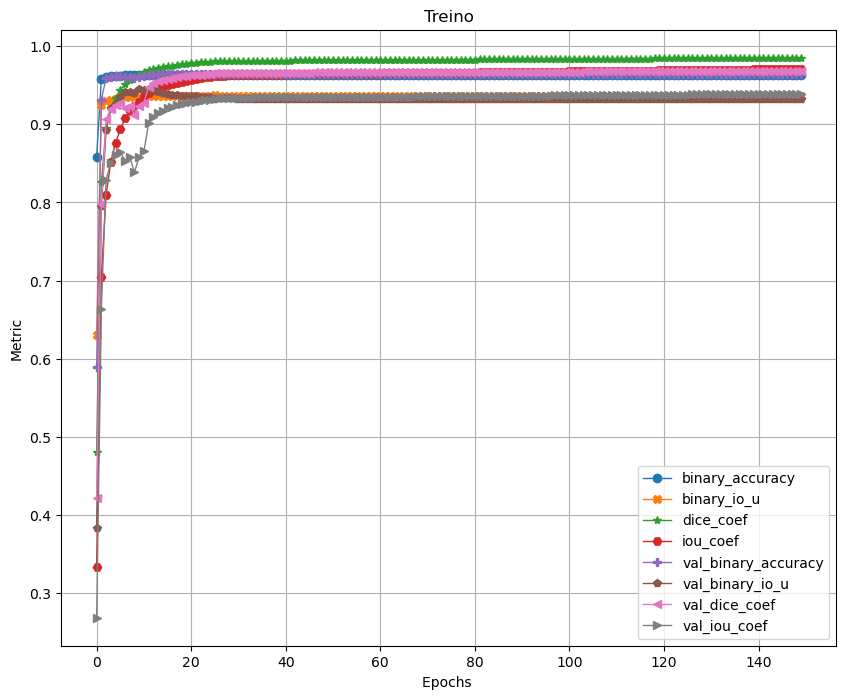

In [14]:
plot_cnn_metrics(model_history)

In [16]:
model = load_model("unet_model.h5", custom_objects={
    "dice_coef": dice_coef,
    "iou_coef": iou_coef
})

In [17]:
loss, binary_accuracy, binary_io_u, dice_coef, iou_coef = model.evaluate(X_test, y_test)

3/3 [==============================] - 2s 420ms/step - loss: 0.0221 - binary_accuracy: 0.9638 - binary_io_u: 0.9339 - dice_coef: 0.9623 - iou_coef: 0.9274


In [18]:
print("Qtd train files: ", len(X_train))

Qtd train files:  171


In [19]:
print("Qtd train files: ", len(X_test))

Qtd train files:  74


In [20]:
print("Loss:", loss)
print("Accuracy:", binary_accuracy)
print("Binary IoU:", binary_io_u)
print("Dice:", dice_coef)
print("IoU:", iou_coef)

Loss: 0.022075606510043144
Accuracy: 0.9638001322746277
Binary IoU: 0.9339226484298706
Dice: 0.9623369574546814
IoU: 0.9274097084999084


In [21]:
y_pred = model.predict(X_test)
y_pred_thresholded = y_pred >= 0.5

3/3 [==============================] - 2s 389ms/step


In [22]:
iou = MeanIoU(num_classes=2)  

iou.update_state(y_pred_thresholded, y_test)

print("Mean IoU =", iou.result().numpy())

Mean IoU = 0.93392265


## Conjunto de Teste / Previsões

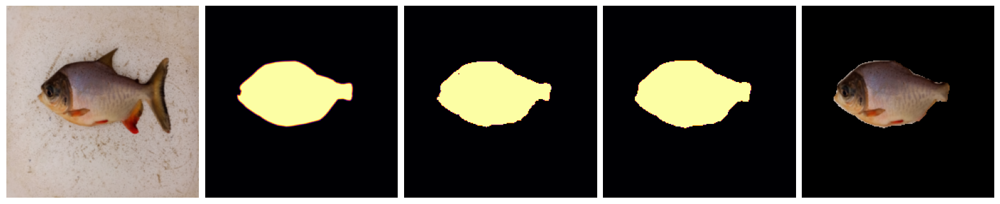

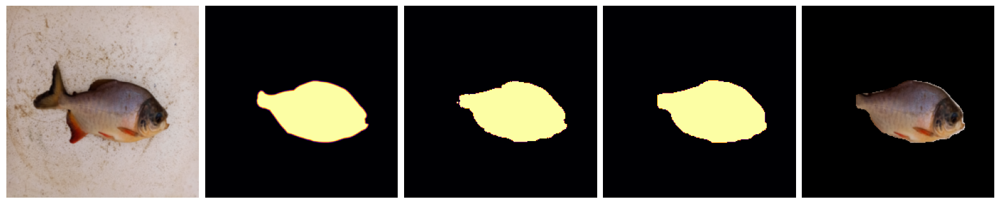

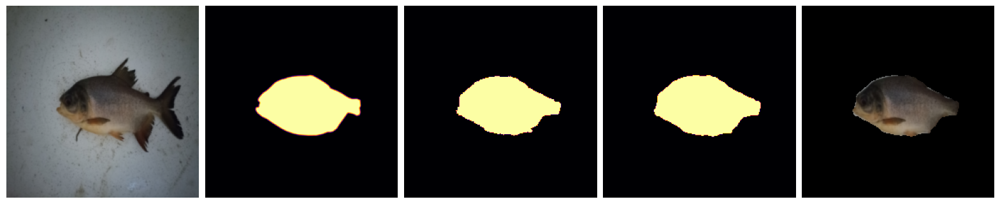

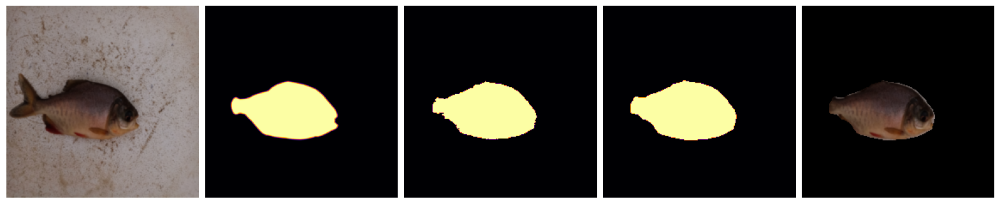

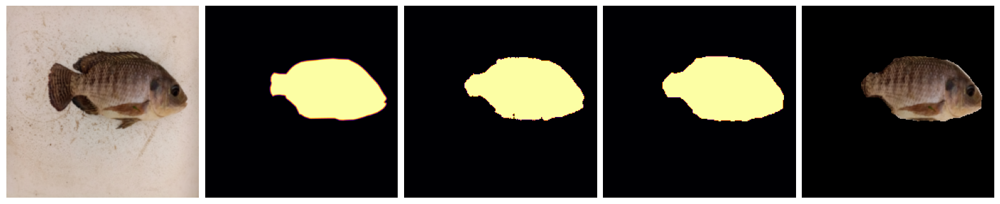

...

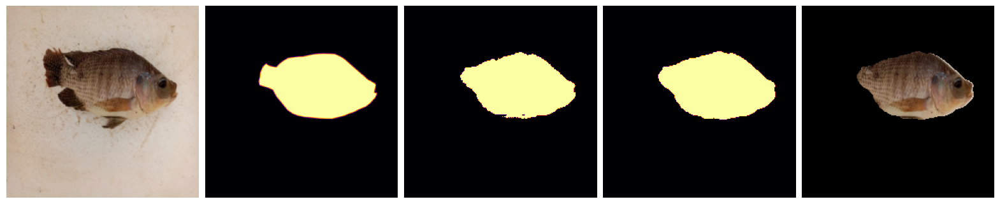

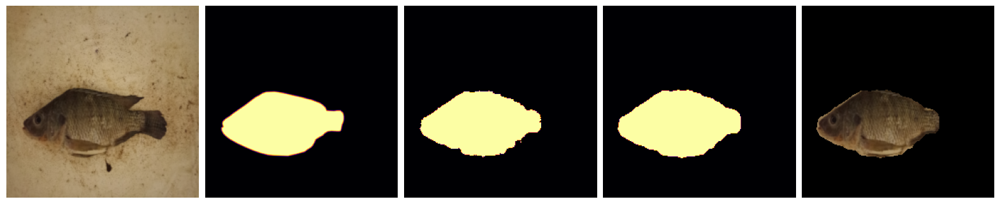

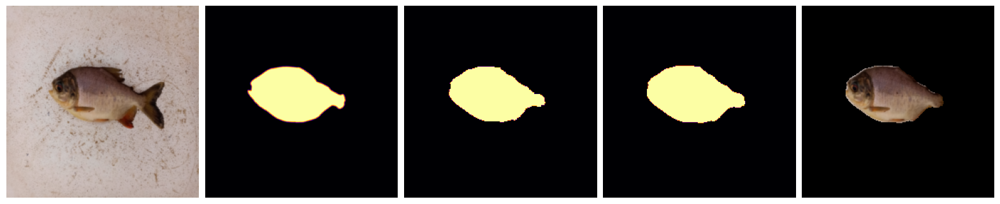

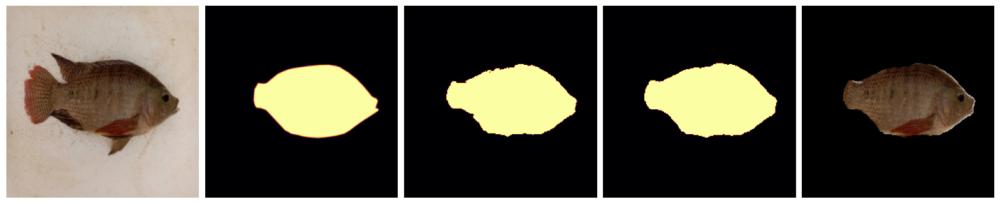

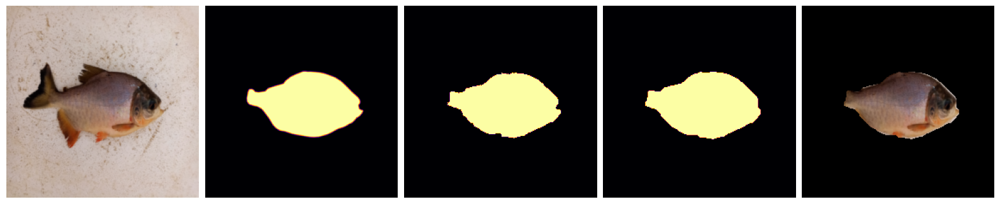

In [23]:
for index in range(len(y_pred)):
    
    predict_mask = y_pred_thresholded[index][:, :, 0].astype('uint8')
    original_mask = y_test[index]
    
    mask_smoothed = smoothing_mask(predict_mask)
    
    image = X_test[index]
    
    merged = merge_image_mask(image, mask_smoothed)
    
    plot([image, 
          original_mask,
          predict_mask,
          mask_smoothed,
          merged], (1, 5))

## Mostrando o conjunto de Treino

6/6 [==============================] - 3s 540ms/step


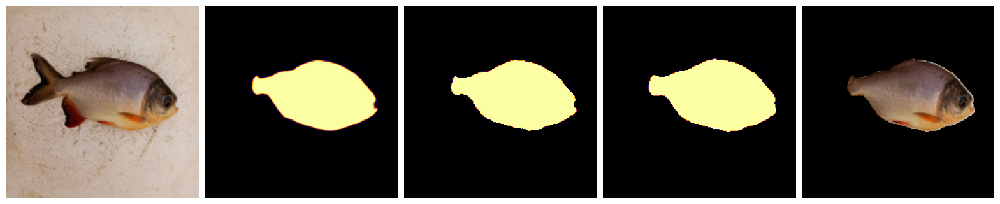

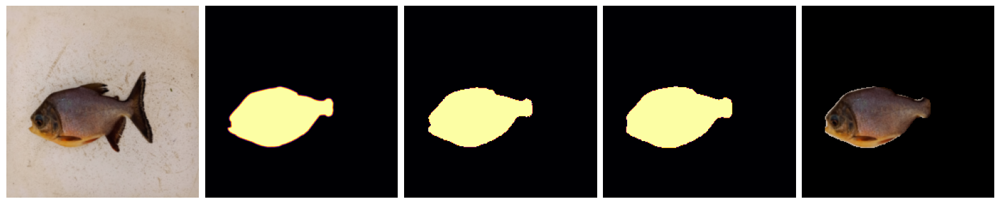

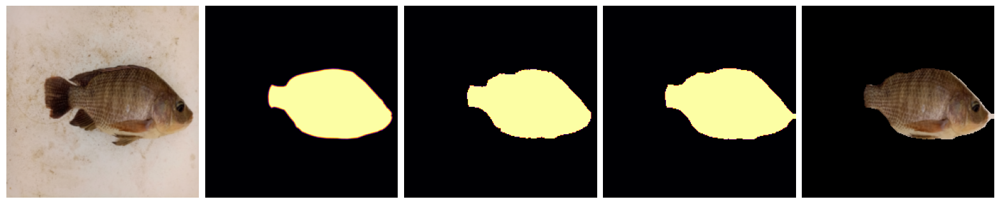

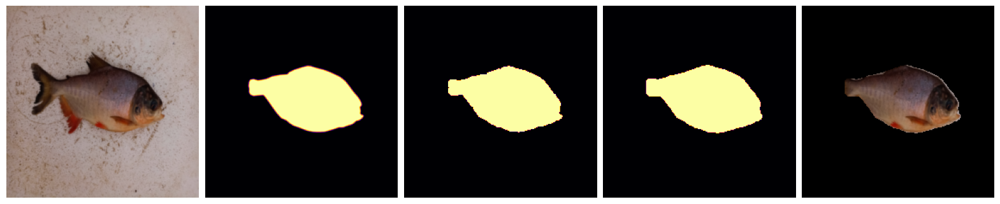

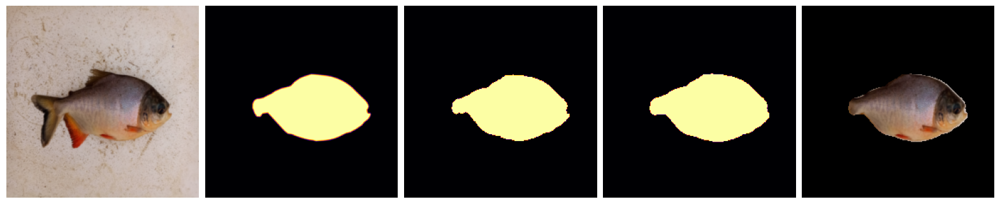

...

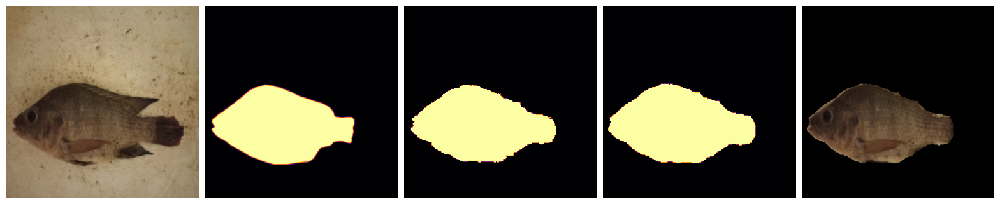

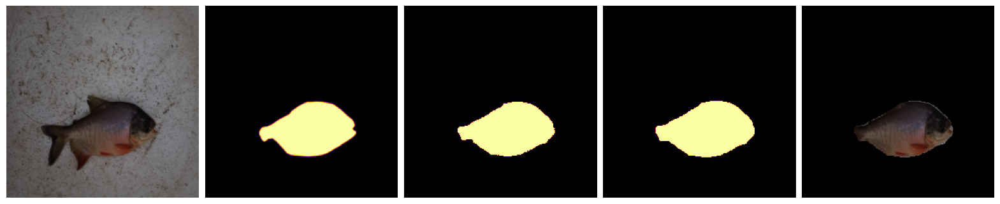

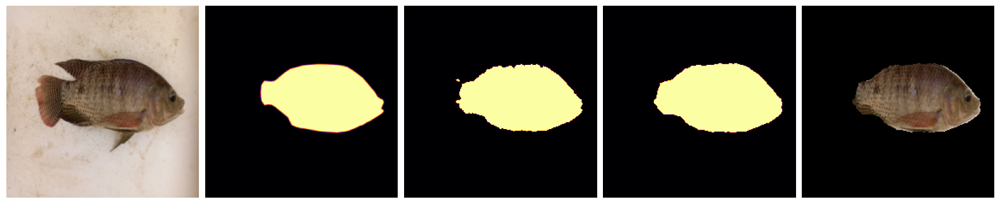

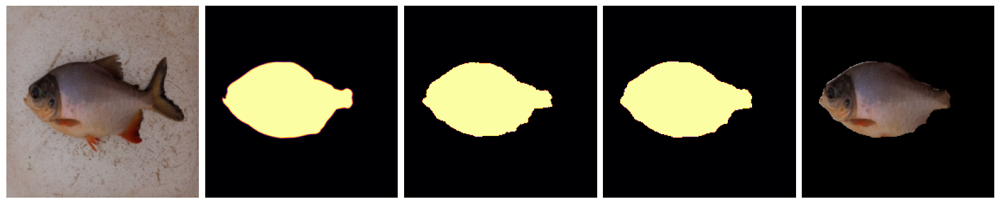

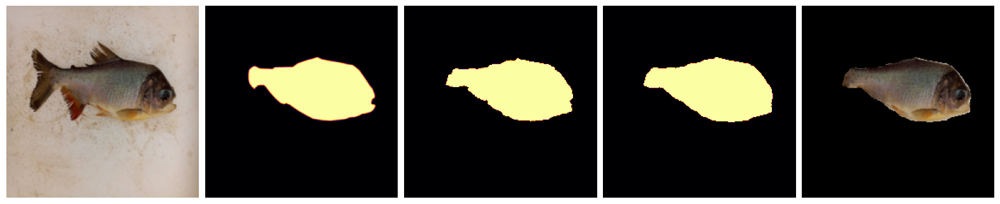

In [24]:
y_pred = model.predict(X_train)
y_pred_thresholded = y_pred >= 0.5

for index in range(len(y_pred)):
    
    predict_mask = y_pred_thresholded[index][:, :, 0].astype('uint8')
    original_mask = y_train[index]
    
    mask_smoothed = smoothing_mask(predict_mask)
    
    image = X_train[index]
    
    merged = merge_image_mask(image, mask_smoothed)
    
    plot([image, 
          original_mask,
          predict_mask,
          mask_smoothed,
          merged], (1, 5))